<a href="https://colab.research.google.com/github/nandpatel31/AI_ASSIGNMENT/blob/main/Stroke_Final.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [3]:
# LOGISTIC REGRESSION HEALTHCARE STROKE PREDICTION MODEL
# =========================================================================================================================================================

import numpy as np              # Designed for high-speed numerical and scientific computing
import pandas as pd             # Designed for data manipulation, cleaning, and analysis.
import matplotlib.pyplot as plt # Creating static, animated, and interactive data visualizations.
import seaborn as sns           # making statistical data visualizations.

from sklearn.model_selection import train_test_split # Split arrays or matrices into random train and test subsets.
from sklearn.preprocessing import StandardScaler, OneHotEncoder # Standardize features by removing the mean and scaling to unit variance.
                                                                # OneHotEncoder
from sklearn.compose import ColumnTransformer # Applies transformers to columns of an array or pandas DataFrame.
from sklearn.linear_model import LogisticRegression # Creates the logistic regression model used to predict outcomes.
from sklearn.metrics import classification_report, confusion_matrix, roc_auc_score
# classification_report evaluates precision, recall, and accuracy.
# confusion_matrix compares actual outcomes with predicted outcomes.
# roc_auc_score how well the model recognises between the two classes.

In [4]:
import pandas as pd # Import pandas to work and to analyse
from google.colab import files # Import the files fucntion to upload into Google Collab

uploaded = files.upload() # Allow the usr to upload the dataset

file_name = next(iter(uploaded))
df = pd.read_csv(file_name)

print("Dataset loaded successfully")
print("Rows and columns:", df.shape)

Saving Stroke.zip to Stroke (1).zip
Dataset loaded successfully
Rows and columns: (5110, 12)


In [5]:
print(df.head()) # Displays the first 5 rows of the dataset.

      id  gender   age  hypertension  heart_disease ever_married  \
0   9046    Male  67.0             0              1          Yes   
1  51676  Female  61.0             0              0          Yes   
2  31112    Male  80.0             0              1          Yes   
3  60182  Female  49.0             0              0          Yes   
4   1665  Female  79.0             1              0          Yes   

       work_type Residence_type  avg_glucose_level   bmi   smoking_status  \
0        Private          Urban             228.69  36.6  formerly smoked   
1  Self-employed          Rural             202.21   NaN     never smoked   
2        Private          Rural             105.92  32.5     never smoked   
3        Private          Urban             171.23  34.4           smokes   
4  Self-employed          Rural             174.12  24.0     never smoked   

   stroke  
0       1  
1       1  
2       1  
3       1  
4       1  


In [6]:
# Inspect Dataset
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5110 entries, 0 to 5109
Data columns (total 12 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   id                 5110 non-null   int64  
 1   gender             5110 non-null   object 
 2   age                5110 non-null   float64
 3   hypertension       5110 non-null   int64  
 4   heart_disease      5110 non-null   int64  
 5   ever_married       5110 non-null   object 
 6   work_type          5110 non-null   object 
 7   Residence_type     5110 non-null   object 
 8   avg_glucose_level  5110 non-null   float64
 9   bmi                4909 non-null   float64
 10  smoking_status     5110 non-null   object 
 11  stroke             5110 non-null   int64  
dtypes: float64(3), int64(4), object(5)
memory usage: 479.2+ KB


In [7]:
# Checks for missing values in each column before cleaning.
print("Missing values before cleaning:")
print(df.isnull().sum())

Missing values before cleaning:
id                     0
gender                 0
age                    0
hypertension           0
heart_disease          0
ever_married           0
work_type              0
Residence_type         0
avg_glucose_level      0
bmi                  201
smoking_status         0
stroke                 0
dtype: int64


In [8]:
# Display the column names
print(df.columns.tolist())

['id', 'gender', 'age', 'hypertension', 'heart_disease', 'ever_married', 'work_type', 'Residence_type', 'avg_glucose_level', 'bmi', 'smoking_status', 'stroke']


In [9]:
# Calculate the median BMI
bmi_median = df["bmi"].median()

# Fill missing BMI values with the median
df["bmi"] = df["bmi"].fillna(bmi_median)

# Display missing values after cleaning
print("Missing values after BMI cleaning:")
print(df.isnull().sum())

Missing values after BMI cleaning:
id                   0
gender               0
age                  0
hypertension         0
heart_disease        0
ever_married         0
work_type            0
Residence_type       0
avg_glucose_level    0
bmi                  0
smoking_status       0
stroke               0
dtype: int64


In [10]:
# Count duplicated rows
print("Number of duplicated rows:", df.duplicated().sum())

Number of duplicated rows: 0


In [11]:
# Reload the dataset to ensure we have the original columns
df = pd.read_csv(file_name)

# Drop 'id' if it exists as we did earlier
if 'id' in df.columns:
    df = df.drop(columns=['id'])

# Fill missing BMI values with the median
bmi_median = df['bmi'].median()
df['bmi'] = df['bmi'].fillna(bmi_median)

# Convert categorical columns into numbers using dummy variables
df = pd.get_dummies(
    df,
    columns=["gender", "ever_married", "work_type", "Residence_type", "smoking_status"],
    drop_first=True
)

# Display the first few rows of the transformed dataset
display(df.head())

,age,hypertension,heart_disease,avg_glucose_level,bmi,stroke,gender_Male,gender_Other,ever_married_Yes,work_type_Never_worked,work_type_Private,work_type_Self-employed,work_type_children,Residence_type_Urban,smoking_status_formerly smoked,smoking_status_never smoked,smoking_status_smokes
0,67.0,0,1,228.69,36.6,1,True,False,True,False,True,False,False,True,True,False,False
1,61.0,0,0,202.21,28.1,1,False,False,True,False,False,True,False,False,False,True,False
2,80.0,0,1,105.92,32.5,1,True,False,True,False,True,False,False,False,False,True,False
3,49.0,0,0,171.23,34.4,1,False,False,True,False,True,False,False,True,False,False,True
4,79.0,1,0,174.12,24.0,1,False,False,True,False,False,True,False,False,False,True,False


In [12]:
# Separate features and target
X = df.drop("stroke", axis=1)
y = df["stroke"]

print("Features:")
print(X.head())

print("\nTarget:")
print(y.head())

Features:
    age  hypertension  heart_disease  avg_glucose_level   bmi  gender_Male  \
0  67.0             0              1             228.69  36.6         True   
1  61.0             0              0             202.21  28.1        False   
2  80.0             0              1             105.92  32.5         True   
3  49.0             0              0             171.23  34.4        False   
4  79.0             1              0             174.12  24.0        False   

   gender_Other  ever_married_Yes  work_type_Never_worked  work_type_Private  \
0         False              True                   False               True   
1         False              True                   False              False   
2         False              True                   False               True   
3         False              True                   False               True   
4         False              True                   False              False   

   work_type_Self-employed  work_type_ch

In [13]:
# Import train_test_split
from sklearn.model_selection import train_test_split

# Split the data into 80% training and 20% testing
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

# Display the training and testing data sizes
print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

Training data: (4088, 16)
Testing data: (1022, 16)


In [14]:
# Import StandardScaler
from sklearn.preprocessing import StandardScaler

# Select numerical columns for scaling
columns_to_scale = ["age", "avg_glucose_level", "bmi"]

# Create the scaler
scaler = StandardScaler()

# Scale the training data
X_train[columns_to_scale] = scaler.fit_transform(X_train[columns_to_scale])

# Scale the testing data
X_test[columns_to_scale] = scaler.transform(X_test[columns_to_scale])

# Display the first five rows
print(X_train.head())

           age  hypertension  heart_disease  avg_glucose_level       bmi  \
845   0.205661             0              0          -0.819973  0.542609   
3744 -1.254901             0              0           0.352075 -1.016163   
4183  1.046590             0              0           0.090662 -0.513749   
3409  0.028623             0              0          -0.903944 -0.526632   
284  -1.299160             0              0          -0.529834  0.349372   

      gender_Male  gender_Other  ever_married_Yes  work_type_Never_worked  \
845         False         False              True                   False   
3744         True         False             False                   False   
4183        False         False              True                   False   
3409         True         False              True                   False   
284          True         False             False                   False   

      work_type_Private  work_type_Self-employed  work_type_children  \
845     

In [15]:
# Display the dataset size
print("Dataset shape:")
print(df.shape)

# Display information about the dataset
print("\nData information:")
print(df.info())

Dataset shape:
(5110, 17)

Data information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5110 entries, 0 to 5109
Data columns (total 17 columns):
 #   Column                          Non-Null Count  Dtype  
---  ------                          --------------  -----  
 0   age                             5110 non-null   float64
 1   hypertension                    5110 non-null   int64  
 2   heart_disease                   5110 non-null   int64  
 3   avg_glucose_level               5110 non-null   float64
 4   bmi                             5110 non-null   float64
 5   stroke                          5110 non-null   int64  
 6   gender_Male                     5110 non-null   bool   
 7   gender_Other                    5110 non-null   bool   
 8   ever_married_Yes                5110 non-null   bool   
 9   work_type_Never_worked          5110 non-null   bool   
 10  work_type_Private               5110 non-null   bool   
 11  work_type_Self-employed         5110 non-null   bo

In [16]:
# Count duplicate records
print("Number of duplicate records:")
print(df.duplicated().sum())

Number of duplicate records:
0


In [17]:
# Display the number of stroke and non-stroke cases
print("Stroke class distribution:")
print(df["stroke"].value_counts())

# Display the percentage of each stroke category
print("\nStroke percentages:")
print((df["stroke"].value_counts(normalize=True) * 100).round(2))

Stroke class distribution:
stroke
0    4861
1     249
Name: count, dtype: int64

Stroke percentages:
stroke
0    95.13
1     4.87
Name: proportion, dtype: float64


In [18]:
# Import Logistic Regression
from sklearn.linear_model import LogisticRegression

# Create a balanced Logistic Regression model
model = LogisticRegression(
    class_weight="balanced",
    max_iter=1000,
    random_state=42
)

# Confirm that the model has been created
print("Balanced Logistic Regression model created.")

Balanced Logistic Regression model created.


In [19]:
# Check missing values after cleaning
print("Final missing values:")
print(df.isnull().sum())

# Check duplicate records
print("\nFinal duplicate count:")
print(df.duplicated().sum())

# Display the final stroke distribution
print("\nFinal stroke distribution:")
print(df["stroke"].value_counts())

Final missing values:
age                               0
hypertension                      0
heart_disease                     0
avg_glucose_level                 0
bmi                               0
stroke                            0
gender_Male                       0
gender_Other                      0
ever_married_Yes                  0
work_type_Never_worked            0
work_type_Private                 0
work_type_Self-employed           0
work_type_children                0
Residence_type_Urban              0
smoking_status_formerly smoked    0
smoking_status_never smoked       0
smoking_status_smokes             0
dtype: int64

Final duplicate count:
0

Final stroke distribution:
stroke
0    4861
1     249
Name: count, dtype: int64


In [20]:
# Separate the input features from the target
X = df.drop(columns=["stroke"])
y = df["stroke"]

# Display the feature columns
print("Features:")
print(X.columns.tolist())

# Display the target column
print("\nTarget:")
print(y.name)

Features:
['age', 'hypertension', 'heart_disease', 'avg_glucose_level', 'bmi', 'gender_Male', 'gender_Other', 'ever_married_Yes', 'work_type_Never_worked', 'work_type_Private', 'work_type_Self-employed', 'work_type_children', 'Residence_type_Urban', 'smoking_status_formerly smoked', 'smoking_status_never smoked', 'smoking_status_smokes']

Target:
stroke


In [21]:
# Split the data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

# Display the number of training and testing records
print("Training records:", X_train.shape[0])
print("Testing records:", X_test.shape[0])

Training records: 4088
Testing records: 1022


In [22]:
# Create the Logistic Regression model
model = LogisticRegression(
    class_weight="balanced",
    max_iter=1000,
    random_state=42
)

# Confirm that the model was created
print("Logistic Regression model created successfully.")

Logistic Regression model created successfully.


In [23]:
# Train the Logistic Regression model using the scaled training features
model.fit(X_train, y_train)

# Confirm that the model has been trained
print("Model trained successfully.")

Model trained successfully.


In [24]:
# Make predictions using the testing data
y_pred = model.predict(X_test)

# Display the prediction results
print("Predictions generated successfully.")
print(y_pred[:20])

Predictions generated successfully.
[0 0 0 0 1 0 0 0 0 0 1 0 1 0 0 0 0 0 0 0]


In [25]:
# Import accuracy_score from sklearn.metrics
from sklearn.metrics import accuracy_score

# Calculate the model accuracy
accuracy = accuracy_score(y_test, y_pred)

# Display the accuracy as a percentage
print("Model Accuracy:", round(accuracy * 100, 2), "%")

Model Accuracy: 74.66 %


In [26]:
# Calculate the model accuracy
accuracy = accuracy_score(y_test, y_pred)

# Display the model accuracy
print("Model Accuracy:", round(accuracy * 100, 2), "%")

# Display the classification report
print(classification_report(y_test, y_pred))

Model Accuracy: 74.66 %
              precision    recall  f1-score   support

           0       0.99      0.74      0.85       972
           1       0.14      0.80      0.24        50

    accuracy                           0.75      1022
   macro avg       0.56      0.77      0.54      1022
weighted avg       0.94      0.75      0.82      1022



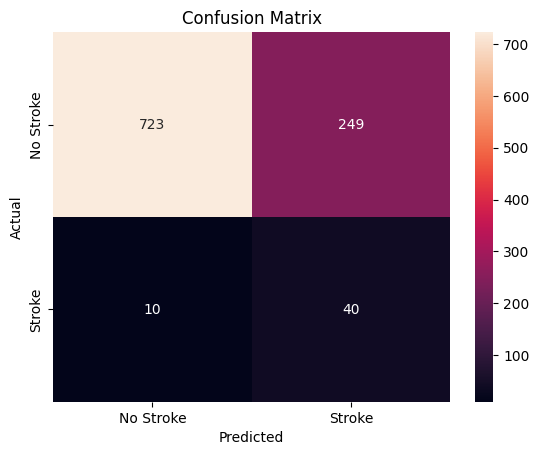

In [27]:
# Import the required libraries
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix

# Create the confusion matrix
cm = confusion_matrix(y_test, y_pred)

# Display the confusion matrix as a heatmap
sns.heatmap(cm, annot=True, fmt="d",
            xticklabels=["No Stroke", "Stroke"],
            yticklabels=["No Stroke", "Stroke"])

# Add labels and title
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix")

# Display the chart
plt.show()

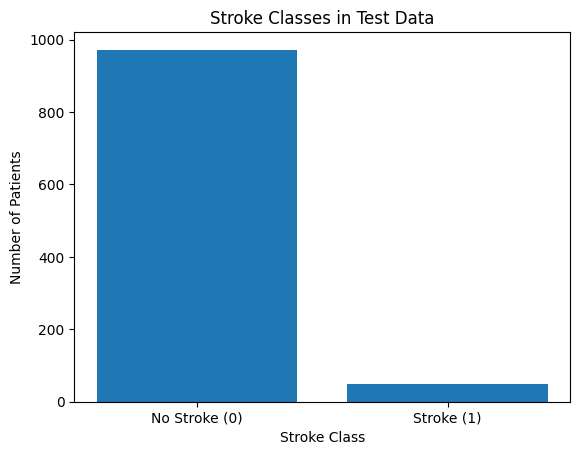

In [28]:
# Count the number of patients in each stroke category
actual_counts = y_test.value_counts().sort_index()

# Create a bar chart
plt.bar(
    ["No Stroke (0)", "Stroke (1)"],
    actual_counts.values
)

# Add the chart title and labels
plt.title("Stroke Classes in Test Data")
plt.xlabel("Stroke Class")
plt.ylabel("Number of Patients")

# Display the chart
plt.show()

In [29]:
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, classification_report

# Create a copy of the splits to scale the numeric columns correctly
X_train_scaled = X_train.copy()
X_test_scaled = X_test.copy()

columns_to_scale = ["age", "avg_glucose_level", "bmi"]
scaler = StandardScaler()

# Fit and transform the numerical features
X_train_scaled[columns_to_scale] = scaler.fit_transform(X_train[columns_to_scale])
X_test_scaled[columns_to_scale] = scaler.transform(X_test[columns_to_scale])

# Create and train the initial model (baseline, unbalanced)
initial_model = LogisticRegression(max_iter=1000, random_state=42)
initial_model.fit(X_train_scaled, y_train)

# Make predictions
y_pred_initial = initial_model.predict(X_test_scaled)

# Display accuracy and results
print("Initial Model Accuracy:", round(accuracy_score(y_test, y_pred_initial) * 100, 2), "%")
print("\nClassification Report:")
print(classification_report(y_test, y_pred_initial))

Initial Model Accuracy: 95.21 %

Classification Report:
              precision    recall  f1-score   support

           0       0.95      1.00      0.98       972
           1       1.00      0.02      0.04        50

    accuracy                           0.95      1022
   macro avg       0.98      0.51      0.51      1022
weighted avg       0.95      0.95      0.93      1022



In [30]:
# Display the initial model accuracy
print("Initial Accuracy:", round(accuracy_score(y_test, y_pred_initial) * 100, 2), "%")

Initial Accuracy: 95.21 %


In [31]:
# Fill missing BMI values with the median
df["bmi"] = df["bmi"].fillna(df["bmi"].median())

# Remove duplicate records
df = df.drop_duplicates()

# Check missing BMI values and duplicates
print("Missing BMI:", df["bmi"].isnull().sum())
print("Duplicates:", df.duplicated().sum())

Missing BMI: 0
Duplicates: 0


In [32]:
# Create the refined Logistic Regression model with class balancing
refined_model = LogisticRegression(class_weight="balanced", max_iter=1000, random_state=42)

# Train the refined model using the correctly scaled training features
refined_model.fit(X_train_scaled, y_train)

# Confirm that the model is trained
print("Refined model trained.")

Refined model trained.


In [33]:
# Create the refined Logistic Regression model with regularization (C=0.5)
refined_model = LogisticRegression(class_weight="balanced", C=0.5, max_iter=1000, random_state=42)

# Train the model with scaled training features
refined_model.fit(X_train_scaled, y_train)

LogisticRegression(C=0.5, class_weight='balanced', max_iter=1000,
                   random_state=42)

In [34]:
# Make predictions using the refined model and scaled testing data
y_pred_refined = refined_model.predict(X_test_scaled)

# Display the refined model accuracy
print("Refined Accuracy:", round(accuracy_score(y_test, y_pred_refined) * 100, 2), "%")

# Display the classification report
print(classification_report(y_test, y_pred_refined))

Refined Accuracy: 74.46 %
              precision    recall  f1-score   support

           0       0.99      0.74      0.85       972
           1       0.14      0.80      0.23        50

    accuracy                           0.74      1022
   macro avg       0.56      0.77      0.54      1022
weighted avg       0.94      0.74      0.82      1022



In [35]:
# Display the initial model accuracy
print("Initial:", round(accuracy_score(y_test, y_pred_initial) * 100, 2), "%")

# Display the refined model accuracy
print("Refined:", round(accuracy_score(y_test, y_pred_refined) * 100, 2), "%")

Initial: 95.21 %
Refined: 74.46 %


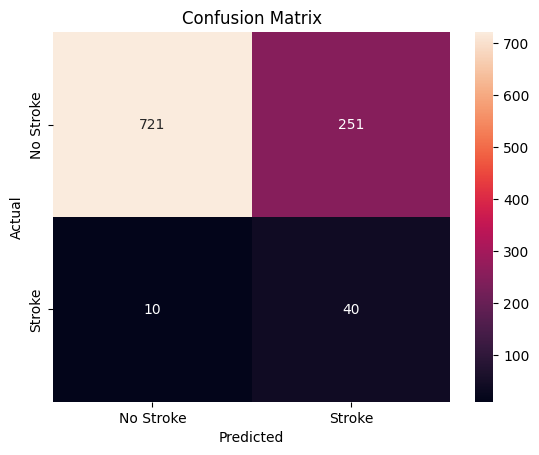

In [36]:
# Import the required libraries
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix

# Create the confusion matrix
cm = confusion_matrix(y_test, y_pred_refined)

# Display the confusion matrix
sns.heatmap(cm, annot=True, fmt="d",
            xticklabels=["No Stroke", "Stroke"],
            yticklabels=["No Stroke", "Stroke"])

# Add labels and title
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix")

# Show the chart
plt.show()